# 01. Data Exploration: ASL Alphabet

**Mục tiêu:** kiểm tra và khám phá dataset trước khi preprocessing và training.

Notebook này chỉ đọc dữ liệu, thống kê và trực quan hóa. Không di chuyển, đổi tên, chỉnh sửa hoặc nhân bản ảnh gốc.

**Dataset dự kiến:**
- `dataset/asl_alphabet_train/`: ảnh train, mỗi lớp nằm trong một thư mục riêng.
- `dataset/asl_alphabet_test/`: tập test (nếu có).

**Nhãn dự kiến:** `A`–`Z`, `space`, `del`/`delete`, `nothing`.

> Notebook nằm trong `notebooks/`, vì vậy đường dẫn `../dataset/` được tính từ thư mục notebook. Nếu cấu trúc thực tế khác, chỉ cần sửa biến `PROJECT_ROOT` ở Cell 2.


## Cell 1. Import thư viện

Nạp các thư viện phục vụ:
- Đọc đường dẫn và kiểm tra file.
- Đọc kích thước ảnh.
- Thống kê dữ liệu bằng DataFrame.
- Vẽ biểu đồ và hiển thị ảnh mẫu.

Chưa sử dụng PyTorch ở bước khám phá dữ liệu.


In [1]:
from pathlib import Path
from collections import Counter
import random

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError

%matplotlib inline

SEED = 42
random.seed(SEED)

print("Libraries imported successfully.")


Libraries imported successfully.


## Cell 2. Khai báo đường dẫn dataset

Notebook giả định cấu trúc dự án:

```text
project/
├── dataset/
│   ├── asl_alphabet_train/
│   └── asl_alphabet_test/
└── notebooks/
    └── 01_data_exploration.ipynb
```

Chỉ khai báo đường dẫn, không tạo hoặc thay đổi thư mục dữ liệu.


In [2]:
PROJECT_ROOT = Path("..").resolve()
DATASET_DIR = PROJECT_ROOT / "dataset"
TRAIN_DIR = DATASET_DIR / "asl_alphabet_train"
TEST_DIR = DATASET_DIR / "asl_alphabet_test"

print("Project root :", PROJECT_ROOT)
print("Dataset dir  :", DATASET_DIR)
print("Train dir    :", TRAIN_DIR)
print("Test dir     :", TEST_DIR)

if not TRAIN_DIR.exists():
    raise FileNotFoundError(
        f"Không tìm thấy thư mục train: {TRAIN_DIR}\n"
        "Hãy kiểm tra cấu trúc thư mục hoặc sửa lại TRAIN_DIR."
    )

print("\nTrain directory found.")
print("Test directory exists:", TEST_DIR.exists())


Project root : C:\Dev\nhan_dien_cu_chi_tay
Dataset dir  : C:\Dev\nhan_dien_cu_chi_tay\dataset
Train dir    : C:\Dev\nhan_dien_cu_chi_tay\dataset\asl_alphabet_train
Test dir     : C:\Dev\nhan_dien_cu_chi_tay\dataset\asl_alphabet_test

Train directory found.
Test directory exists: True


## Cell 3. Kiểm tra cấu trúc thư mục

Liệt kê các thư mục lớp trong tập train và kiểm tra số lượng thư mục.

Với dataset dạng ImageFolder, mỗi thư mục con trực tiếp của `asl_alphabet_train` được xem là một class.


In [3]:
class_dirs = sorted([p for p in TRAIN_DIR.iterdir() if p.is_dir()])

classes = [p.name for p in class_dirs]

print(f"Number of classes: {len(classes)}")
print("Class names:")
for name in classes:
    print("-", name)

print("\nTop-level train entries:")
for item in sorted(TRAIN_DIR.iterdir())[:15]:
    print(item.name, "(folder)" if item.is_dir() else "(file)")


Number of classes: 1
Class names:
- asl_alphabet_train

Top-level train entries:
asl_alphabet_train (folder)


## Cell 4. Thu thập danh sách ảnh và nhãn

Quét các định dạng ảnh phổ biến bên trong từng thư mục lớp.

Mỗi dòng dữ liệu gồm:
- `image_path`: đường dẫn đến ảnh gốc.
- `label`: tên lớp lấy từ tên thư mục.
- `class_dir`: thư mục chứa ảnh.

Không sao chép hay chỉnh sửa ảnh.


In [4]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

records = []

for class_dir in class_dirs:
    for image_path in class_dir.rglob("*"):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({
                "image_path": str(image_path),
                "label": class_dir.name,
                "class_dir": class_dir.name
            })

df = pd.DataFrame(records)

print("Total images:", len(df))
display(df.head())


Total images: 87000


,image_path,label,class_dir
0,C:\Dev\nhan_dien_cu_chi_tay\dataset\asl_alphab...,asl_alphabet_train,asl_alphabet_train
1,C:\Dev\nhan_dien_cu_chi_tay\dataset\asl_alphab...,asl_alphabet_train,asl_alphabet_train
2,C:\Dev\nhan_dien_cu_chi_tay\dataset\asl_alphab...,asl_alphabet_train,asl_alphabet_train
3,C:\Dev\nhan_dien_cu_chi_tay\dataset\asl_alphab...,asl_alphabet_train,asl_alphabet_train
4,C:\Dev\nhan_dien_cu_chi_tay\dataset\asl_alphab...,asl_alphabet_train,asl_alphabet_train


## Cell 5. Kiểm tra số lượng ảnh theo từng lớp

Thống kê số ảnh của từng nhãn để phát hiện:
- Lớp không có ảnh.
- Lớp có quá ít ảnh.
- Mất cân bằng dữ liệu giữa các lớp.


In [5]:
class_counts = (
    df["label"]
    .value_counts()
    .reindex(classes, fill_value=0)
    .sort_index()
)

display(class_counts.rename("image_count").to_frame())

print("Minimum images/class:", class_counts.min())
print("Maximum images/class:", class_counts.max())
print("Mean images/class   :", round(class_counts.mean(), 2))
print("Classes with 0 images:", class_counts[class_counts == 0].index.tolist())


,image_count
label,
asl_alphabet_train,87000


Minimum images/class: 87000
Maximum images/class: 87000
Mean images/class   : 87000.0
Classes with 0 images: []


## Cell 6. Trực quan hóa phân bố dữ liệu

Biểu đồ giúp quan sát nhanh mức độ cân bằng giữa các lớp.

Nếu các cột có chiều cao gần nhau, số lượng ảnh giữa các lớp tương đối đồng đều.


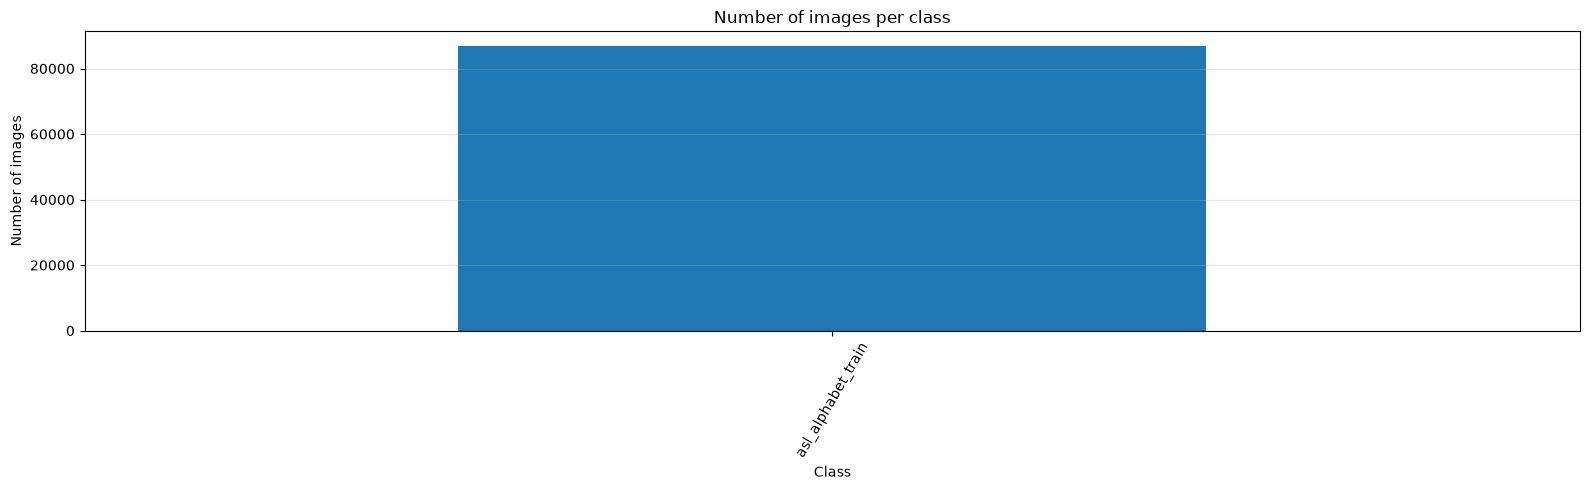

In [6]:
plt.figure(figsize=(16, 5))
class_counts.plot(kind="bar")
plt.title("Number of images per class")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=60)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## Cell 7. Hiển thị ảnh mẫu của từng lớp

Lấy ngẫu nhiên một ảnh trong mỗi lớp để kiểm tra:
- Ảnh có đúng cử chỉ tương ứng với nhãn không.
- Tay có nằm rõ trong khung hình không.
- Có ảnh bất thường hoặc sai nhãn dễ nhận thấy không.

Đây là bước kiểm tra trực quan, chưa phải đánh giá chất lượng nhãn hoàn chỉnh.


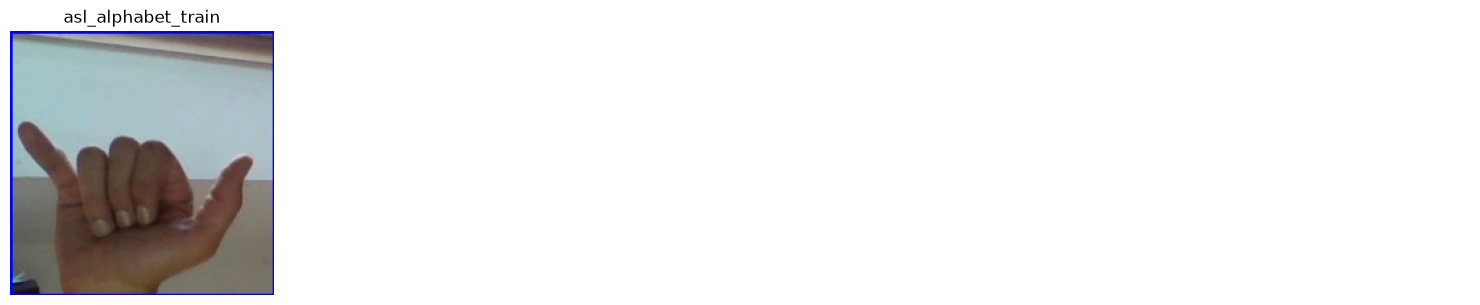

In [7]:
available_classes = [name for name in classes if class_counts.get(name, 0) > 0]

n_cols = 5
n_rows = (len(available_classes) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3 * n_rows))
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for ax in axes:
    ax.axis("off")

for ax, class_name in zip(axes, available_classes):
    paths = df.loc[df["label"] == class_name, "image_path"].tolist()
    image_path = random.choice(paths)

    with Image.open(image_path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()


## Cell 8. Kiểm tra kích thước ảnh

Thống kê chiều rộng, chiều cao và mode màu của ảnh.

Thông tin này giúp quyết định kích thước resize và cách chuẩn hóa ở giai đoạn preprocessing. Không resize ảnh gốc trong notebook này.


In [8]:
sample_paths = df["image_path"].tolist()
dimension_records = []

for image_path in sample_paths:
    try:
        with Image.open(image_path) as image:
            width, height = image.size
            dimension_records.append({
                "image_path": image_path,
                "width": width,
                "height": height,
                "mode": image.mode
            })
    except (UnidentifiedImageError, OSError):
        continue

dimensions_df = pd.DataFrame(dimension_records)

display(dimensions_df[["width", "height"]].describe())
print("\nImage modes:")
display(dimensions_df["mode"].value_counts().to_frame("count"))

print("\nMost common image sizes:")
display(
    dimensions_df.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(10)
    .to_frame("count")
)


,width,height
count,87000.0,87000.0
mean,200.0,200.0
std,0.0,0.0
min,200.0,200.0
25%,200.0,200.0
50%,200.0,200.0
75%,200.0,200.0
max,200.0,200.0



Image modes:


,count
mode,
RGB,87000



Most common image sizes:


,,count
width,height,
200,200,87000


## Cell 9. Kiểm tra ảnh lỗi hoặc không đọc được

Mở lần lượt các ảnh để phát hiện file hỏng hoặc không phải ảnh hợp lệ.

Cell này chỉ đọc file. Danh sách ảnh lỗi được lưu trong biến `corrupted_files`, không xóa file.


In [9]:
corrupted_files = []

for image_path in df["image_path"]:
    try:
        with Image.open(image_path) as image:
            image.verify()
    except (UnidentifiedImageError, OSError, ValueError) as error:
        corrupted_files.append({
            "image_path": image_path,
            "error": str(error)
        })

print("Corrupted/unreadable images:", len(corrupted_files))

if corrupted_files:
    display(pd.DataFrame(corrupted_files).head(20))
else:
    print("No corrupted images detected.")


Corrupted/unreadable images: 0
No corrupted images detected.


## Cell 10. Kiểm tra tập test

Tập test có thể được tổ chức khác tập train. Cell này chỉ kiểm tra cấu trúc và đếm ảnh, không giả định test bắt buộc phải chia thư mục theo class.

Nếu test không tồn tại, notebook vẫn tiếp tục được.


In [10]:
if TEST_DIR.exists():
    test_files = [
        p for p in TEST_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    test_subdirs = sorted([p.name for p in TEST_DIR.iterdir() if p.is_dir()])

    print("Test images:", len(test_files))
    print("Test subfolders:", test_subdirs[:30])

    if test_subdirs:
        test_class_counts = {
            folder: sum(
                1 for p in (TEST_DIR / folder).rglob("*")
                if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
            )
            for folder in test_subdirs
        }
        display(pd.Series(test_class_counts, name="image_count").to_frame())
    else:
        print("Test folder appears to contain images directly, not class subfolders.")
else:
    print("Test directory not found. Skipping test-set inspection.")


Test images: 28
Test subfolders: ['asl_alphabet_test']


,image_count
asl_alphabet_test,28


## Cell 11. Tổng kết kết quả khám phá dữ liệu

Tạo bảng tổng quan để ghi nhận tình trạng dataset trước khi chuyển sang preprocessing.

Các tiêu chí cần xem:
- Tổng số class và ảnh.
- Số ảnh ít nhất/nhiều nhất trong một class.
- Số ảnh lỗi.
- Tập test có tồn tại hay không.

Đọc kết quả rồi ghi chú các vấn đề cần xử lý ở notebook tiếp theo.


In [11]:
summary = {
    "number_of_classes": len(classes),
    "number_of_train_images": len(df),
    "minimum_images_per_class": int(class_counts.min()) if len(class_counts) else 0,
    "maximum_images_per_class": int(class_counts.max()) if len(class_counts) else 0,
    "corrupted_images": len(corrupted_files),
    "test_directory_exists": TEST_DIR.exists()
}

display(pd.DataFrame([summary]).T.rename(columns={0: "value"}))


,value
number_of_classes,1
number_of_train_images,87000
minimum_images_per_class,87000
maximum_images_per_class,87000
corrupted_images,0
test_directory_exists,True


## Kết luận và bước tiếp theo

Sau khi chạy hết notebook, hãy kiểm tra các kết quả và xác nhận:
1. Các class có đúng tên và đủ số lượng không?
2. Ảnh mẫu có đúng nhãn không?
3. Kích thước ảnh có đồng nhất không?
4. Có ảnh lỗi hoặc ảnh bất thường không?
5. Cấu trúc tập test có phù hợp với cách đánh giá dự kiến không?

**Notebook tiếp theo:** `02_data_preprocessing.ipynb`.

Ở bước tiếp theo mới thực hiện các thao tác phục vụ model như chuyển ảnh sang RGB, resize, chuẩn hóa pixel và tạo DataLoader. Dataset gốc vẫn được giữ nguyên.
